# Testes do artigo: risco de reidentificação em populações pequenas

Este notebook reproduz, em ordem, todos os experimentos do artigo *Quando a anonimização não basta* e mostra as tabelas e figuras correspondentes. Ele apenas chama os scripts do repositório, cada um num processo separado, exatamente como no terminal; os números saem idênticos aos do artigo, porque a semente aleatória é fixa (2026).

**Antes de começar**

- Este arquivo precisa estar na mesma pasta dos scripts (`sim_reidentificacao.py`, `rede_reidentificacao.py` etc.).
- O kernel do Jupyter precisa ser um Python **3.10 a 3.14** com os pacotes do `requirements.txt` (o pgmpy ainda não funciona no 3.15). A primeira célula confere isso.
- Rode as células de cima para baixo (**Shift+Enter**). Enquanto uma célula roda, aparece `[*]` à esquerda; quando termina, aparece um número.
- Tempo total: cerca de 10 minutos. As células mais demoradas estão indicadas.

Todos os dados são sintéticos: nenhum dado pessoal é coletado, lido ou vinculado a pessoas.

## 0. Conferência do ambiente

In [37]:
import sys, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib, scipy, pgmpy
from IPython.display import display, Image, Markdown

print("Python    ", sys.version.split()[0], "|", platform.system(), platform.release())
print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("matplotlib", matplotlib.__version__)
print("scipy     ", scipy.__version__)
print("pgmpy     ", pgmpy.__version__)
assert Path("sim_reidentificacao.py").exists(), "Coloque este notebook na pasta dos scripts."
assert sys.version_info[:2] < (3, 15), "Use um kernel Python 3.10 a 3.14 (o pgmpy 1.1 não roda no 3.15)."
pd.set_option("display.precision", 3)

import os, subprocess, time
def rodar(script):
    # roda o script num processo separado, igual a rodá-lo no terminal
    t0 = time.perf_counter()
    env = dict(os.environ, PYTHONIOENCODING="utf-8", MPLBACKEND="Agg")
    r = subprocess.run([sys.executable, "-W", "ignore::FutureWarning", script],
                       capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr)
        raise RuntimeError(f"{script} terminou com erro (veja a mensagem acima).")
    print(f"[{script} concluído em {time.perf_counter() - t0:.0f} s]")

print("\nAmbiente OK.")

Python     3.13.17 | Windows 11
numpy      2.5.4
pandas     3.1.1
matplotlib 3.11.2
scipy      1.18.1
pgmpy      1.1.2

Ambiente OK.


## 1. Simulação da unicidade (E1 a E3)

A rede geradora produz turmas sintéticas com sete quase-identificadores. Para cada desenho de questionário (D0 a D3), mede-se a proporção de respondentes únicos por simulação de Monte Carlo e por expressões analíticas.

⏱ **Esta célula leva de 3 a 5 minutos e não mostra nada até terminar.**

In [20]:
rodar("sim_reidentificacao.py")

Python 3.13.17 | numpy 2.5.4 | pandas 3.1.1 | matplotlib 3.11.2
SO: Windows 11 | CPU: Intel64 Family 6 Model 165 Stepping 2, GenuineIntel
Semente: 2026 | Repetições: 2000
Tempo E1: 181.4 s | Tempo E2+E3: 80.7 s | Total: 262.1 s


[sim_reidentificacao.py concluído em 264 s]


**E1. Respondentes únicos por tamanho da turma** (Monte Carlo × expressão analítica)

In [21]:
e1 = pd.read_csv("resultados/E1_tamanho_turma.csv")
tab = e1.pivot(index="N", columns="desenho", values="prop_unicos_MC") * 100
display(tab.round(1).style.format("{:.1f}%").set_caption("Únicos (%) por N e desenho"))
dif = (e1.prop_unicos_MC - e1.prop_unicos_analitico).abs().max() * 100
print(f"Diferença máxima entre Monte Carlo e expressão analítica: {dif:.2f} ponto percentual")

desenho,D0,D1,D2,D3
N,,,,
10,99.9%,99.2%,96.0%,82.4%
15,99.8%,98.6%,94.0%,74.5%
20,99.8%,98.3%,91.5%,67.0%
30,99.7%,97.5%,87.7%,56.2%
50,99.6%,96.1%,80.6%,40.2%
100,99.0%,92.3%,66.4%,20.8%
500,95.2%,73.6%,25.6%,2.8%
5000,70.8%,30.7%,3.1%,0.2%


Diferença máxima entre Monte Carlo e expressão analítica: 0.54 ponto percentual


**E2. Acúmulo de quase-identificadores** (N = 30, desenho D0)

In [22]:
e2 = pd.read_csv("resultados/E2_numero_qi.csv")
e2["únicos (%)"] = (100 * e2.prop_unicos).round(1)
e2["k < 5 (%)"] = (100 * e2.prop_k_menor_5).round(1)
display(e2[["num_QI", "QI_incluidos", "únicos (%)", "k < 5 (%)"]])

,num_QI,QI_incluidos,únicos (%),k < 5 (%)
0,1,genero,1.2,2.1
1,2,genero+raca,6.7,29.4
2,3,genero+raca+idade,79.6,100.0
3,4,genero+raca+idade+formacao,96.2,100.0
4,5,genero+raca+idade+formacao+linha,98.6,100.0
5,6,genero+raca+idade+formacao+linha+vinculo,99.0,100.0
6,7,genero+raca+idade+formacao+linha+vinculo+cidade,99.7,100.0


**E3. Resposta incompleta** (60% de adesão, N = 30)

In [23]:
e3 = pd.read_csv("resultados/E3_resposta_incompleta.csv")
display((e3.set_index("desenho")[["respondentes", "prop_unicos_na_turma",
         "precisao_unico_amostra", "risco_medio_respondentes"]]).round(3))

,respondentes,prop_unicos_na_turma,precisao_unico_amostra,risco_medio_respondentes
desenho,,,,
D0,18.006,0.997,0.999,0.998
D1,18.037,0.974,0.991,0.987
D2,18.000,0.877,0.949,0.936
D3,18.048,0.559,0.801,0.751


## 2. Sensibilidade aos parâmetros (E4)

Quatro cenários de composição da turma, do heterogêneo (S1) ao muito homogêneo (S3). ⏱ Cerca de 30 segundos.

In [24]:
rodar("sensibilidade.py")

desenho                           D0     D1     D2     D3
cenario                                                  
S0 Base                        0.997  0.975  0.876  0.561
S1 Heterogênea (pessimista)    1.000  0.997  0.855  0.539
S2 Homogênea                   0.926  0.684  0.583  0.342
S3 Muito homogênea (otimista)  0.610  0.343  0.281  0.160
desenho                               D0     D1     D2     D3
cenario                       N                              
S0 Base                       15   0.999  0.988  0.937  0.745
                              50   0.995  0.959  0.804  0.403
                              100  0.990  0.922  0.663  0.210
S1 Heterogênea (pessimista)   15   1.000  0.998  0.926  0.730
                              50   0.999  0.995  0.775  0.382
                              100  0.999  0.989  0.622  0.209
S2 Homogênea                  15   0.962  0.780  0.718  0.506
                              50   0.885  0.610  0.479  0.237
                              10

In [25]:
e4 = pd.read_csv("resultados/E4_sensibilidade.csv")
t = e4[e4.N == 30].pivot(index="desenho", columns="cenario", values="prop_unicos") * 100
display(t.round(1).style.format("{:.1f}%").set_caption("Únicos (%) com N = 30"))

cenario,S0 Base,S1 Heterogênea (pessimista),S2 Homogênea,S3 Muito homogênea (otimista)
desenho,,,,
D0,99.7%,100.0%,92.6%,61.0%
D1,97.5%,99.7%,68.4%,34.3%
D2,87.6%,85.5%,58.3%,28.1%
D3,56.1%,53.9%,34.2%,16.0%


## 3. Rede bayesiana de reidentificação (E5 e E6)

Rede: desenho (*D*), tamanho da turma (*N*) e composição (*S*) → classe de equivalência (*F*); *F* e tipo de adversário (*K*) → reidentificação (*Re*). A tabela de *F* é calculada a partir da rede geradora. A célula faz inferência preditiva e diagnóstica, verifica d-separações, compara observar e intervir e busca a explicação mais relevante (MRE).

⏱ **Cerca de 3 a 4 minutos.**

In [26]:
rodar("rede_reidentificacao.py")

A1
 N     15     30     100    500
D                             
D0  0.960  0.931  0.869  0.784
D1  0.862  0.826  0.758  0.655
D2  0.833  0.770  0.625  0.394
D3  0.719  0.608  0.390  0.238
P(F=1|D,N)
 N     15     30     100    500
D                             
D0  0.926  0.883  0.806  0.697
D1  0.798  0.750  0.662  0.524
D2  0.741  0.649  0.445  0.175
D3  0.558  0.401  0.153  0.028
prior P(Re=sim|N=30) = 0.4253
A2
   variavel   estado  posteriori  priori
0        D       D0       0.299    0.25
1        D       D1       0.265    0.25
2        D       D2       0.245    0.25
3        D       D3       0.190    0.25
4        S       S1       0.294    0.25
5        S       S0       0.295    0.25
6        S       S2       0.244    0.25
7        S       S3       0.167    0.25
8        K  interno       0.921    0.50
9        K  externo       0.079    0.50
A3 {'D ⊥ K': True, 'D ⊥ K | Re': False, 'D ⊥ Re | F': True, 'N ⊥ S': True, 'N ⊥ S | F': False} MB(F) = ['D', 'K', 'N', 'Re', 'S']
P(K=inte

**Tabela 4 do artigo:** P(Re = sim | D, N, K = interno)

In [27]:
a1 = pd.read_csv("resultados/A1_preditiva.csv")
display((a1.pivot(index="D", columns="N", values="P_Re_sim") * 100).round(1)
        .style.format("{:.1f}%"))

N,15,30,100,500
D,,,,
D0,96.0%,93.1%,86.9%,78.4%
D1,86.2%,82.6%,75.8%,65.5%
D2,83.3%,77.0%,62.5%,39.4%
D3,71.9%,60.8%,39.0%,23.8%


**Inferência diagnóstica:** dado Re = sim numa turma de 30

In [28]:
a2 = pd.read_csv("resultados/A2_diagnostica.csv")
display(a2.round(3))

,variavel,estado,posteriori,priori
0,D,D0,0.299,0.25
1,D,D1,0.265,0.25
2,D,D2,0.245,0.25
3,D,D3,0.190,0.25
4,S,S1,0.294,0.25
5,S,S0,0.295,0.25
6,S,S2,0.244,0.25
7,S,S3,0.167,0.25
8,K,interno,0.921,0.50
9,K,externo,0.079,0.50


**Tabela 5 do artigo:** observar × intervir (variante com confundimento N → D)

In [29]:
a4 = pd.read_csv("resultados/A4_observar_intervir.csv").set_index("D")
display((a4 * 100).round(1).rename(columns={"P_Re_obs": "P(Re | D)", "P_Re_do": "P(Re | do(D))"}))
print(f"Diferença D0 − D3 ao observar: {100*(a4.P_Re_obs['D0']-a4.P_Re_obs['D3']):.1f} p.p.")
print(f"Diferença D0 − D3 ao intervir: {100*(a4.P_Re_do['D0']-a4.P_Re_do['D3']):.1f} p.p.")

,P(Re | D),P(Re | do(D))
D,,
D0,85.7,88.6
D1,76.5,77.5
D2,68.5,65.5
D3,58.0,48.9


Diferença D0 − D3 ao observar: 27.7 p.p.
Diferença D0 − D3 ao intervir: 39.7 p.p.


**Explicação mais relevante (MRE):** explicações mínimas dado Re = sim

In [30]:
display(pd.read_csv("resultados/A5_mre_minimas.csv").round(3))
display(Markdown("Com o adversário interno fixado (busca sobre D, N, S):"))
display(pd.read_csv("resultados/A5_mre_interno_minimas.csv").round(3))

,explicacao,priori,posteriori,r,GBF
0,K=interno,0.5,0.924,1.849,12.202


Com o adversário interno fixado (busca sobre D, N, S):

,explicacao,priori,posteriori,r,GBF
0,"D=D0, S=S1",0.062,0.089,1.425,1.466
1,"D=D0, S=S0",0.062,0.088,1.415,1.455
2,"D=D1, S=S1",0.062,0.088,1.414,1.454
3,"D=D1, N=15, S=S0",0.016,0.022,1.417,1.427
4,"D=D1, N=30, S=S0",0.016,0.022,1.408,1.417
5,"D=D0, N=15, S=S2",0.016,0.022,1.398,1.407
6,"D=D2, N=30, S=S0",0.016,0.021,1.334,1.341


## 4. Sensibilidade da MRE às hipóteses arbitradas

Refaz a MRE variando P(K = interno) e a chance de o adversário externo vincular um registro único. ⏱ Cerca de 1 a 2 minutos.

In [31]:
rodar("sensibilidade_mre.py")

    P_K_interno  P_externo_unico      melhor_explicacao  GBF_melhor  GBF_K_interno  posteriori_K_interno                                                                                                                                                                                                                                                                                                                 minimas
0          0.10             0.05              K=interno      24.404         24.404                 0.731                                                                                                                                                                                                                                                                                                               K=interno
1          0.10             0.10              K=interno      12.202         12.202                 0.576                                                              

In [32]:
a6 = pd.read_csv("resultados/A6_sensibilidade_mre.csv")
display(a6.pivot(index="P_externo_unico", columns="P_K_interno", values="melhor_explicacao"))

P_K_interno,0.10,0.25,0.50,0.75,0.90
P_externo_unico,,,,,
0.05,K=interno,K=interno,K=interno,K=interno,K=interno
0.10,K=interno,K=interno,K=interno,K=interno,K=interno
0.25,"D=D0, S=S1, K=interno",K=interno,K=interno,K=interno,K=interno
0.50,"D=D0, S=S1, K=interno","D=D0, S=S1, K=interno",K=interno,K=interno,K=interno
1.00,"D=D0, S=S1","D=D0, S=S1","D=D0, S=S1","D=D0, S=S1","D=D0, S=S1"


## 5. Aprendizado de estrutura (E7)

Com quantos respondentes os algoritmos PC e Hill Climbing (BIC) recuperam a estrutura da rede geradora? ⏱ Cerca de 1 minuto.

In [33]:
rodar("aprendizado_estrutura.py")

   metodo     N  ...  falsos_pos  SHD_medio
0  HC-BIC    30  ...        0.20       1.55
1  HC-BIC   100  ...        0.05       1.05
2  HC-BIC   300  ...        0.00       1.00
3  HC-BIC  1000  ...        0.00       0.05
4  HC-BIC  5000  ...        0.00       0.00
5      PC    30  ...        0.45       1.95
6      PC   100  ...        0.50       0.90
7      PC   300  ...        0.35       0.45
8      PC  1000  ...        0.20       0.20
9      PC  5000  ...        0.30       0.30

[10 rows x 6 columns]
tempo: 33.0 s

[aprendizado_estrutura.py concluído em 49 s]


## 6. Figuras do artigo

ok
ok

[figuras_artigo.py concluído em 3 s]


**fig_E1_tamanho**

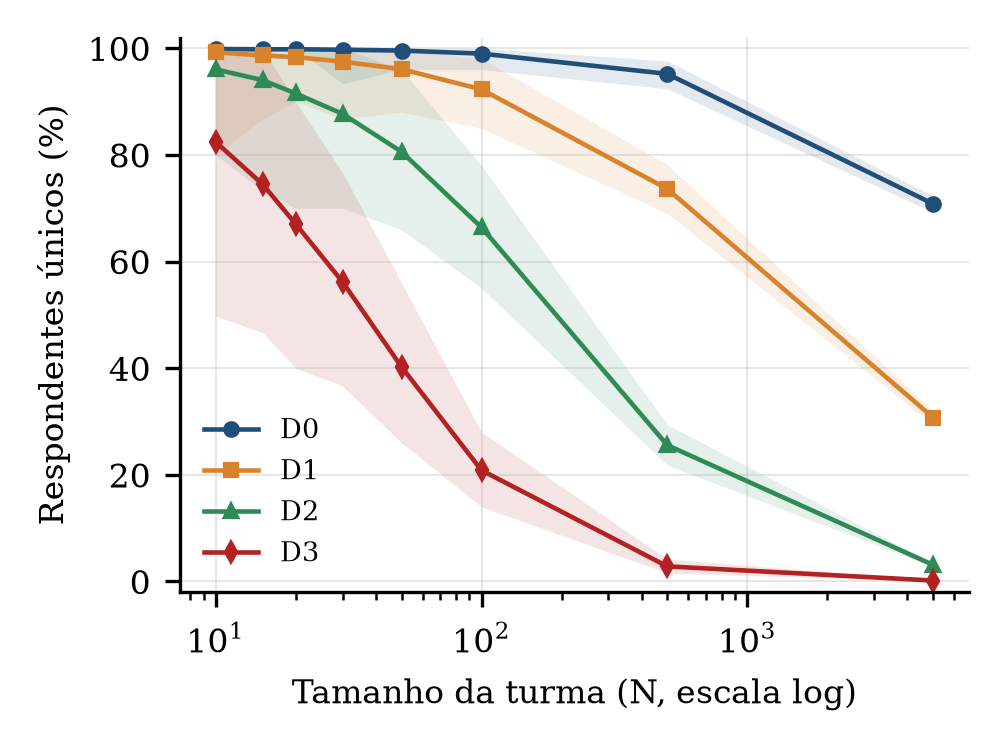

**fig_E2_numero_qi**

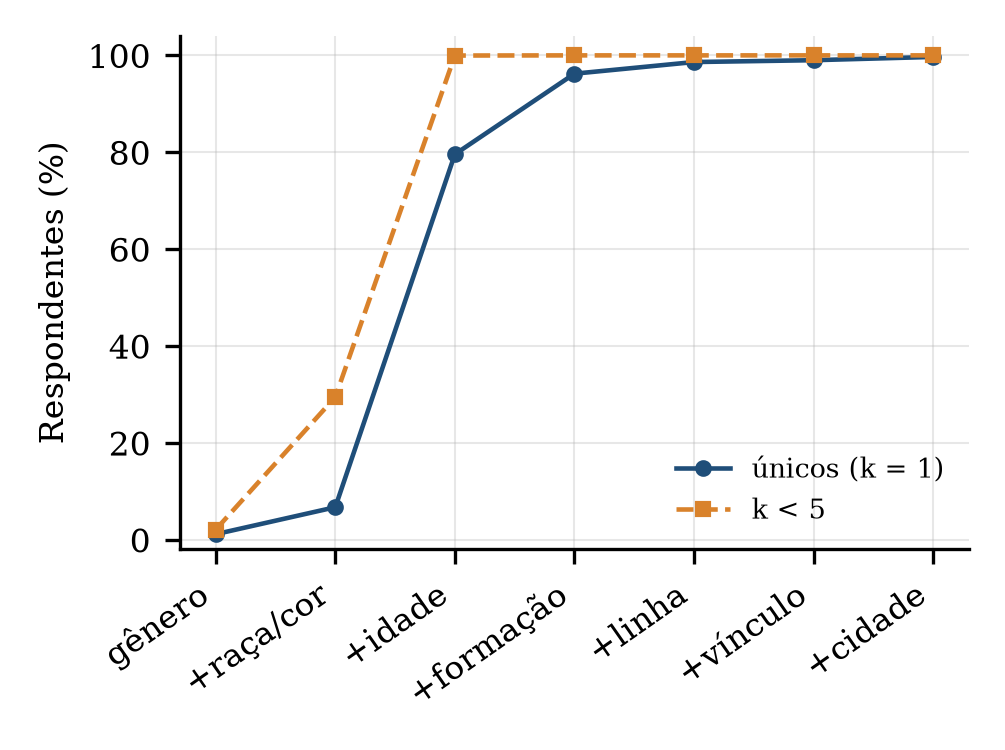

**fig_E4_sensibilidade**

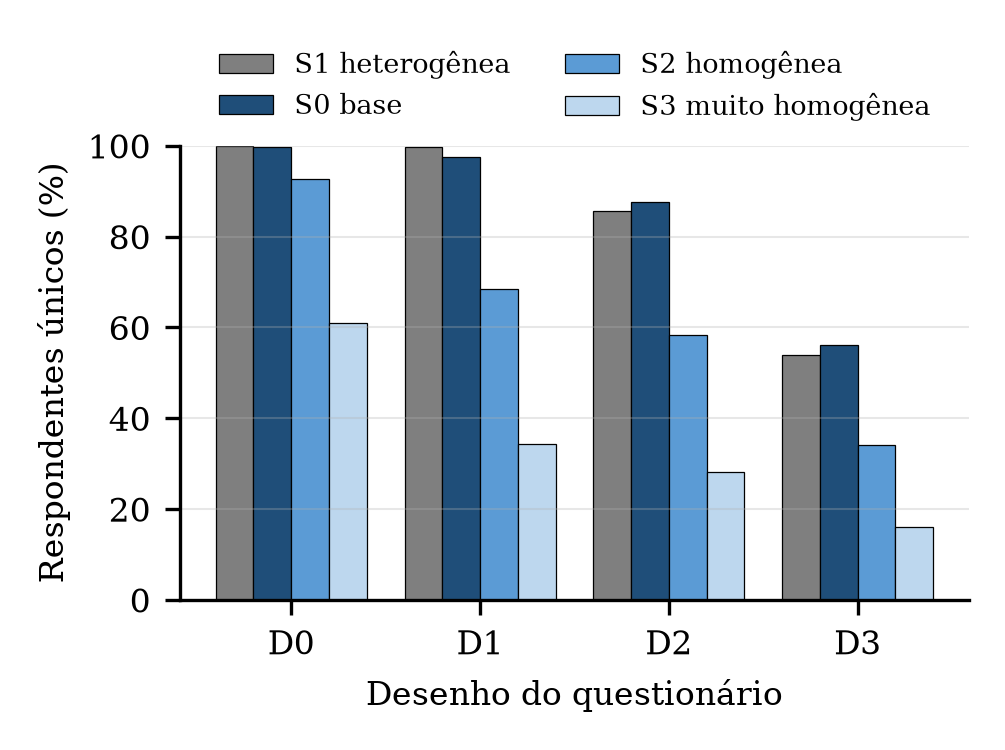

**fig_E7_estrutura**

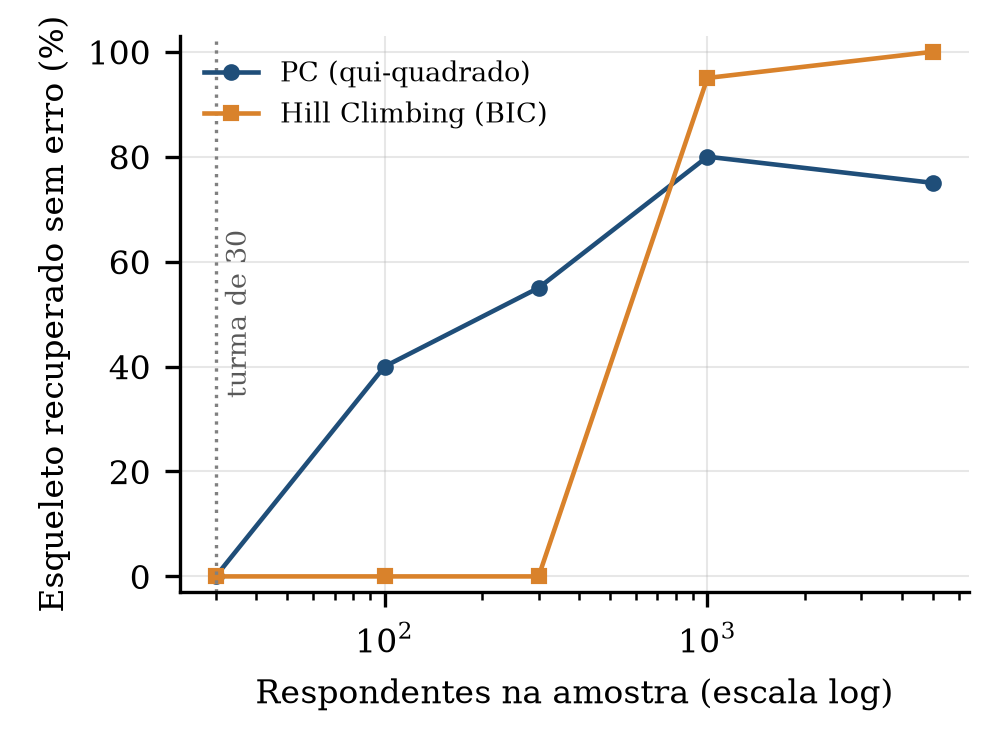

In [34]:
rodar("figuras_artigo.py")
for f in ["fig_E1_tamanho", "fig_E2_numero_qi", "fig_E4_sensibilidade", "fig_E7_estrutura"]:
    display(Markdown(f"**{f}**"))
    display(Image(filename=f"figuras/{f}.png", width=480))

## 7. Tempos de execução

In [35]:
print(open("resultados/ambiente.txt", encoding="utf-8").read())

Python 3.13.17 | numpy 2.5.4 | pandas 3.1.1 | matplotlib 3.11.2
SO: Windows 11 | CPU: Intel64 Family 6 Model 165 Stepping 2, GenuineIntel
Semente: 2026 | Repetições: 2000
Tempo E1: 181.4 s | Tempo E2+E3: 80.7 s | Total: 262.1 s
Sensibilidade (E4): 24.0 s | conferência MC S3/D3/N=30: MC=0.1618 x analítico=0.1596
Rede de reidentificação (A1-A5): 194.4 s
Sensibilidade da MRE (A6): 108.5 s
Aprendizado de estrutura (B1): 33.0 s



## 8. Experimente você mesmo

A rede de reidentificação já está pronta na memória. Mude os valores abaixo e rode a célula para ver como a probabilidade de reidentificação responde. Isso não altera os resultados do artigo.

- `desenho`: "D0", "D1", "D2" ou "D3"
- `tamanho`: "15", "30", "100" ou "500" (entre aspas)
- `adversario`: "interno" ou "externo"

In [42]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from pgmpy.inference import VariableElimination
import rede_reidentificacao as rr

desenho, tamanho, adversario = "D3", "30", "interno"

if "rede" not in globals():
    rede = rr.montar_rede()          # calcula a CPT de F (cerca de 1 minuto na primeira vez)
ve = VariableElimination(rede)
q = ve.query(["Re"], evidence={"D": desenho, "N": tamanho, "K": adversario}, show_progress=False)
print(f"P(Re = sim | D={desenho}, N={tamanho}, K={adversario}) = {rr.p(q, 'sim'):.3f}")

P(Re = sim | D=D3, N=30, K=interno) = 0.608
